<a href="https://colab.research.google.com/github/physicsYTU/FIZ4610-Computational-Physics/blob/main/numerik_turev_python.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Numerical Derivative

Bu Jupyter Notebook, Python temellerini (sayı üretimi, filtreleme, fonksiyon yazma) ve sayısal analizde kritik bir öneme sahip olan **Numerik Türev (Numerical Differentiation)** yöntemlerini (İleri Fark - FDA, Geri Fark - BDA, Merkezî Fark - CDA) öğrenmeniz için hazırlanmıştır.





## 1. 1'den 100'e Kadar Sayı Üretimi ve Filtreleme

Öncelikle Python'da `range()` fonksiyonunu kullanarak 1'den 100'e kadar olan sayıları listeleyelim. Ardından liste üreteçleri (list comprehensions) yardımıyla önce tek, sonra çift sayıları ayıralım.

In [ ]:
# 1'den 100'e kadar olan sayılar (100 dahil)
tum_sayilar = list(range(1, 101))

# Tek sayılar (2'ye bölümünden kalan 1 olanlar)
tek_sayilar = [x for x in tum_sayilar if x % 2 != 0]

# Çift sayılar (2'ye bölümünden kalan 0 olanlar)
cift_sayilar = [x for x in tum_sayilar if x % 2 == 0]

print(f"İlk 5 Tek Sayı: {tek_sayilar[:5]}")
print(f"İlk 5 Çift Sayı: {cift_sayilar[:5]}")

İlk 5 Tek Sayı: [1, 3, 5, 7, 9]
İlk 5 Çift Sayı: [2, 4, 6, 8, 10]


In [ ]:
x = range(6)
for n in x:
  print(n)

0
1
2
3
4
5


Create a sequence of numbers from 3 to 5, and print each item in the sequence:



In [ ]:
x = range(3, 6)
for n in x:
  print(n)

3
4
5


Create a sequence of numbers from 3 to 19, but increment by 2 instead of 1:



In [ ]:
x = range(3, 20, 2)
for n in x:
  print(n)

3
5
7
9
11
13
15
17
19


In [ ]:
# Example with two arguments
for i in range(-1, 5):
    print(i, end=", ") # prints: -1, 0, 1, 2, 3, 4,

-1, 0, 1, 2, 3, 4, 

In [ ]:
# More complex example
for i in [1, 3, 5, 7, 9]:
    x = i**2 - (i-1)*(i+2)**i
    print(x, end=", ")              # prints 1, 1, 1, 1, 1,

1, -241, -67203, -28697765, -18863581447, 

## 2. Python'da Fonksiyon Yazmak

Python'da tekrar eden işlemleri modüler hale getirmek için `def` anahtar kelimesi ile fonksiyonlar tanımlarız.

- **`def`**: Fonksiyon tanımlamanın başlangıcıdır.
- **Parametreler**: Fonksiyona dışarıdan gönderilen girdilerdir.
- **`return`**: Fonksiyonun hesaplama sonucunu dışarıya döndürmesini sağlar.

Örnek olarak girdiğimiz bir $x$ değerinin karesini alan basit bir fonksiyon yazalım:

In [ ]:
def ornek_fonksiyon(x):
    """
    Bu fonksiyon verilen x değerinin karesini hesaplar.
    f(x) = x^2
    """
    return x ** 2

# Fonksiyonu test edelim
x=4.2
sonuc = ornek_fonksiyon(x)
print(sonuc)
print("sonuc=", sonuc)
print('sonuc=',sonuc)
print(f"f({x}) = {sonuc}")

17.64
sonuc= 17.64
sonuc= 17.64
f(4.2) = 17.64


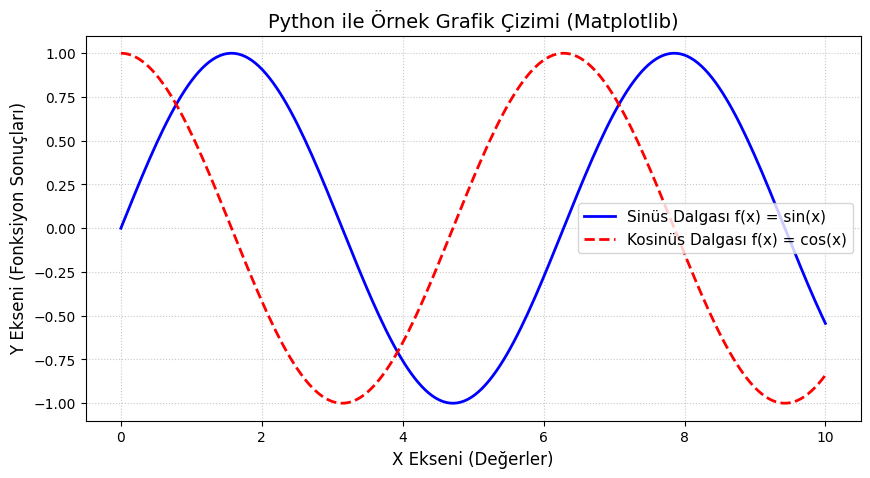

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# 1. X ekseni için 0 ile 10 arasında 200 adet eşit aralıklı sayı üretelim
x = np.linspace(0, 10, 200)

# 2. Bu x değerlerine karşılık gelen y fonksiyonlarını hesaplayalım
y1 = np.sin(x)
y2 = np.cos(x)

# 3. Grafik penceresini boyutlandıralım
plt.figure(figsize=(10, 5))

# 4. Çizgi grafiklerini çizdirelim
plt.plot(x, y1, label="Sinüs Dalgası f(x) = sin(x)", color="blue", linewidth=2)
plt.plot(x, y2, label="Kosinüs Dalgası f(x) = cos(x)", color="red", linestyle="--", linewidth=2)

# 5. Başlık, eksen etiketleri ve açıklama (lejant) ekleyelim
plt.title("Python ile Örnek Grafik Çizimi (Matplotlib)", fontsize=14)
plt.xlabel("X Ekseni (Değerler)", fontsize=12)
plt.ylabel("Y Ekseni (Fonksiyon Sonuçları)", fontsize=12)

# 6. Izgara (grid) ve lejantı aktif edelim
plt.grid(True, linestyle=":", alpha=0.7)
plt.legend(fontsize=11)

# 7. Grafiği ekranda gösterelim
plt.show()


In [ ]:
import numpy as np

aci_degre = 90
aci_radyan = aci_degre * (np.pi / 180)

# Radyan cinsinden kosinüs hesabı
sonuc_rad = np.cos(aci_radyan)

# Dereceyi doğrudan verirseniz Python bunu radyan sanır (90 radyan olarak hesaplar!)
sonuc_deg_hata = np.cos(aci_degre)

print("Radyan cinsinden (90°):", sonuc_rad)
print("Dereceyi doğrudan verme hatası (90 radyan):", sonuc_deg_hata)


Radyan cinsinden (90°): 6.123233995736766e-17
Dereceyi doğrudan verme hatası (90 radyan): -0.4480736161291701


In [ ]:
import numpy as np

# Derece değerlerini NumPy dizisine çeviriyoruz ki matematiksel işlem yapabilelim
aci_degree = np.array([0, 30, 45, 60, 90])
aci_radyan = aci_degree * (np.pi / 180)

sonuc1 = np.cos(aci_radyan)
sonuc2 = np.cos(aci_degree)

# Her bir açıyı tek tek düzgün bir şekilde yazdırmak için döngü kullanabiliriz
print("Açı (Derece)  Kosinüs (Radyan - Doğru)  Kosinüs (Derece - Hatalı)")
print("-" * 70)
for i in range(len(aci_degree)):
    #print(f"{aci_degree[i]:12d}  {sonuc1[i]:24.4f}  {sonuc2[i]:24.4f}")
    print(f"{aci_degree[i]} \t {sonuc1[i]} \t {sonuc2[i]}")

Açı (Derece)  Kosinüs (Radyan - Doğru)  Kosinüs (Derece - Hatalı)
----------------------------------------------------------------------
0 	 1.0 	 1.0
30 	 0.8660254037844387 	 0.15425144988758405
45 	 0.7071067811865476 	 0.5253219888177297
60 	 0.5000000000000001 	 -0.9524129804151563
90 	 6.123233995736766e-17 	 -0.4480736161291701


In [ ]:
import numpy as np

# Derece cinsinden açılar
aci_dereceleri = [0, 30, 45, 60, 90]

print(f"{'Derece':<10} | {'Radyan':<10} | {'Sinüs (Radyan - Doğru)':<25} | {'Sinüs (Derece - Hatalı)':<25}")
print("-" * 80)

for deg in aci_dereceleri:
    # Dereceyi radyana çevir
    rad = np.radians(deg)  # veya deg * (np.pi / 180)

    # Sinüs hesaplamaları
    sin_rad = np.sin(rad)
    sin_deg_hata = np.sin(deg)

    print(f"{deg:<10} | {rad:<10.4f} | {sin_rad:<25.4f} | {sin_deg_hata:<25.4f}")

Derece     | Radyan     | Sinüs (Radyan - Doğru)    | Sinüs (Derece - Hatalı)  
--------------------------------------------------------------------------------
0          | 0.0000     | 0.0000                    | 0.0000                   
30         | 0.5236     | 0.5000                    | -0.9880                  
45         | 0.7854     | 0.7071                    | 0.8509                   
60         | 1.0472     | 0.8660                    | -0.3048                  
90         | 1.5708     | 1.0000                    | 0.8940                   


## 3. Numerik Türev Nedir? (FDA, BDA, CDA)

Analitik olarak türevini alamadığımız veya karmaşık olan fonksiyonların türevini bilgisayar yardımıyla sayısal (numerik) olarak yaklaşıksal hesaplarız. Temel fark denklemleri şunlardır:

1. **İleri Fark Yöntemi (Forward Difference Approximation - FDA):**
   $$f'(x) \approx \frac{f(x + h) - f(x)}{h}$$

2. **Geri Fark Yöntemi (Backward Difference Approximation - BDA):**
   $$f'(x) \approx \frac{f(x) - f(x - h)}{h}$$

3. **Merkezî Fark Yöntemi (Central Difference Approximation - CDA) [Daha yüksek doğruluk]:**
   $$f'(x) \approx \frac{f(x + h) - f(x - h)}{2h}$$

İkinci mertebeden türev (Second Derivative) için merkezî fark formülü:
   $$f''(x) \approx \frac{f(x + h) - 2f(x) + f(x - h)}{h^2}$$

## 4. Python ile Numerik Türev Kodları ve Örnekler

Şimdi farklı fonksiyonlar ($f(x) = x^2$, $f(x) = \sin(x)$ ve $f(x) = e^x$) için 1. ve 2. türevleri hesaplayan fonksiyonlarımızı yazalım ve görselleştirelim.

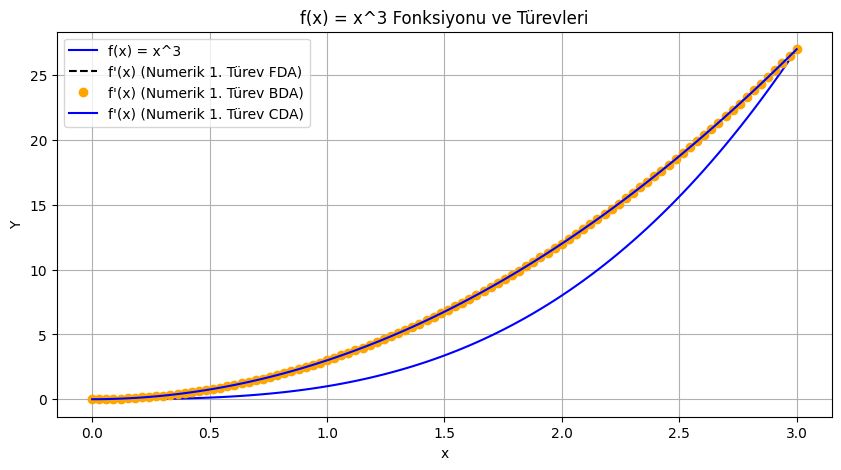

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Türev Hesaplama Fonksiyonları ( FDA)
def birinci_turev_fda(f, x, h=1e-5):
    return (f(x + h) - f(x)) / (h)

#  Türev Hesaplama Fonksiyonları (BDA)
def birinci_turev_bda(f, x, h=1e-5):
    return (f(x ) - f(x - h)) / (h)

#  Türev Hesaplama Fonksiyonları (CDA)
def birinci_turev_cda(f, x, h=1e-5):
    return (f(x + h) - f(x - h)) / (2 * h)

# 2. Türev Hesaplama Fonksiyonu
def ikinci_turev_cda(f, x, h=1e-5):
    return (f(x + h) - 2 * f(x) + f(x - h)) / (h ** 2)

# Farklı test fonksiyonları tanımlayalım
def f1(x): return x**3
def f2(x): return np.sin(x)
def f3(x): return np.exp(x)

# x değer aralığı
x_vals = np.linspace(0, 3, 100)

# Örnek 1: f(x) = x^3 için 1. ve 2. türev
d1_f1 = birinci_turev_fda(f1, x_vals)
d1_f2 = birinci_turev_bda(f1, x_vals)
d1_f3 = birinci_turev_cda(f1, x_vals)
#d2_f1 = ikinci_turev_cda(f1, x_vals)

plt.figure(figsize=(10, 5))
plt.plot(x_vals, f1(x_vals), label="f(x) = x^3", color="blue")
plt.plot(x_vals, d1_f1, label="f'(x) (Numerik 1. Türev FDA)", color="black", linestyle="--")
plt.plot(x_vals, d1_f2, label="f'(x) (Numerik 1. Türev BDA)", color="orange", linestyle="", marker="o")
plt.plot(x_vals, d1_f3, label="f'(x) (Numerik 1. Türev CDA)", color="blue", linestyle="-")

#plt.plot(x_vals, d2_f1, label="f''(x) (Numerik 2. Türev)", color="green", linestyle=":")
plt.title("f(x) = x^3 Fonksiyonu ve Türevleri")
plt.xlabel("x")
plt.ylabel("Y")
plt.legend()
plt.grid(True)
plt.show()

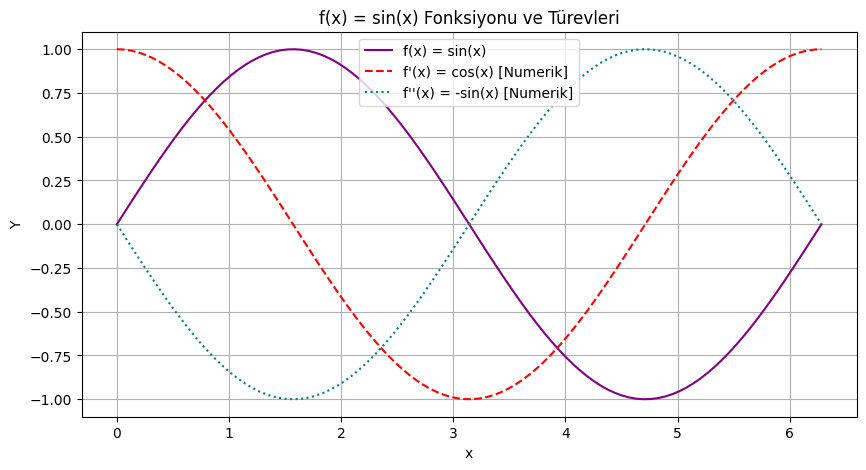

In [ ]:
# Örnek 2: f(x) = sin(x) için türevler
x_tr = np.linspace(0, 2 * np.pi, 100)
d1_sin = birinci_turev_cda(np.sin, x_tr)
d2_sin = ikinci_turev_cda(np.sin, x_tr)

plt.figure(figsize=(10, 5))
plt.plot(x_tr, np.sin(x_tr), label="f(x) = sin(x)", color="purple")
plt.plot(x_tr, d1_sin, label="f'(x) = cos(x) [Numerik]", color="red", linestyle="--")
plt.plot(x_tr, d2_sin, label="f''(x) = -sin(x) [Numerik]", color="teal", linestyle=":")
plt.title("f(x) = sin(x) Fonksiyonu ve Türevleri")
plt.xlabel("x")
plt.ylabel("Y")
plt.legend()
plt.grid(True)
plt.show()

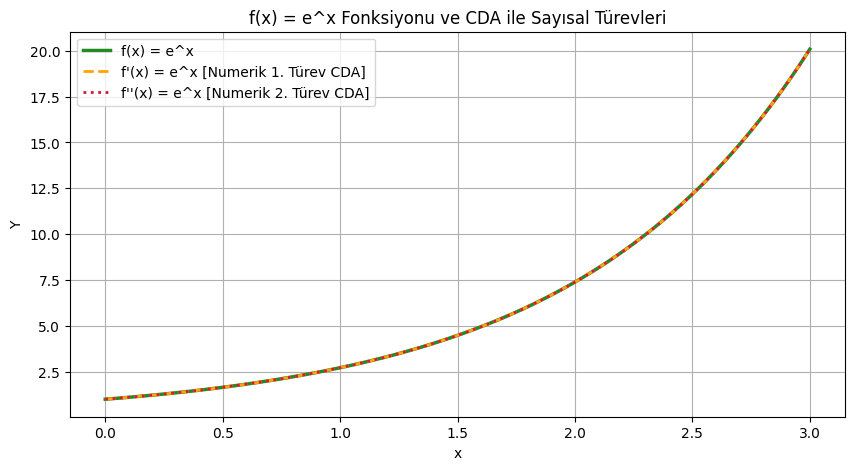

In [ ]:
# Örnek 3: f(x) = e^x için Merkezî Fark (CDA) Türevleri
x_exp = np.linspace(0, 3, 100)

# f(x) = e^x fonksiyonunun kendisi
y_exp = np.exp(x_exp)

# Numerik türev hesaplamaları (CDA kullanarak)
d1_exp = birinci_turev_cda(np.exp, x_exp)
d2_exp = ikinci_turev_cda(np.exp, x_exp)

# Grafik çizimi
plt.figure(figsize=(10, 5))
plt.plot(x_exp, y_exp, label="f(x) = e^x", color="forestgreen", linewidth=2.5)
plt.plot(x_exp, d1_exp, label="f'(x) = e^x [Numerik 1. Türev CDA]", color="orange", linestyle="--", linewidth=2)
plt.plot(x_exp, d2_exp, label="f''(x) = e^x [Numerik 2. Türev CDA]", color="crimson", linestyle=":", linewidth=2)

plt.title("f(x) = e^x Fonksiyonu ve CDA ile Sayısal Türevleri")
plt.xlabel("x")
plt.ylabel("Y")
plt.legend()
plt.grid(True)
plt.show()